# Brain Tumor MRI Classification: TensorFlow
AI Platforms, Assignment 1. Transfer learning (ResNet50V2 main, MobileNetV2 comparison), evaluation, Grad-CAM, export for FastAPI.

In [1]:
import os, time, json, pathlib, random
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, precision_recall_fscore_support, accuracy_score
from PIL import Image

TEAM_ID = "T10"      
SEED, IMG, BATCH = 42, 224, 32
CLASS_NAMES = ["glioma", "meningioma", "notumor", "pituitary"]  
DATA_ROOT = pathlib.Path("../data")     
MODEL_DIR = pathlib.Path("../model"); MODEL_DIR.mkdir(exist_ok=True)
ASSETS = pathlib.Path("report_assets"); ASSETS.mkdir(exist_ok=True)   # figures for the report 

keras.utils.set_random_seed(SEED)
print("TF", tf.__version__, "| Keras", keras.__version__, "| GPUs:", tf.config.list_physical_devices("GPU"))

TF 2.20.0 | Keras 3.12.0 | GPUs: []


## 1. Data and split
Official `Testing/` folder is the held-out test set. `Training/` is split 85/15 (stratified) into train/validation. The split is saved to `splits.csv` so the PyTorch notebook can use identical images.

In [2]:
def list_split(root):
    rows = [(str(p), CLASS_NAMES.index(p.parent.name)) for p in sorted(root.rglob("*"))
            if p.suffix.lower() in {".jpg", ".jpeg", ".png"} and p.parent.name in CLASS_NAMES]
    return pd.DataFrame(rows, columns=["path", "y"])

trainval, test = list_split(DATA_ROOT/"Training"), list_split(DATA_ROOT/"Testing")
train, val = train_test_split(trainval, test_size=0.15, stratify=trainval.y, random_state=SEED)

splits = pd.concat([train.assign(split="train"), val.assign(split="val"), test.assign(split="test")])
splits["path"] = splits.path.map(lambda p: str(pathlib.Path(p).relative_to(DATA_ROOT)))
splits.to_csv("splits.csv", index=False)

summary = pd.DataFrame({n: d.y.map(dict(enumerate(CLASS_NAMES))).value_counts() for n, d in
                        [("train", train), ("val", val), ("test", test)]}).T[CLASS_NAMES]
summary["total"] = summary.sum(axis=1); display(summary)

y,glioma,meningioma,notumor,pituitary,total
train,1190,1190,1190,1190,4760
val,210,210,210,210,840
test,400,400,400,400,1600


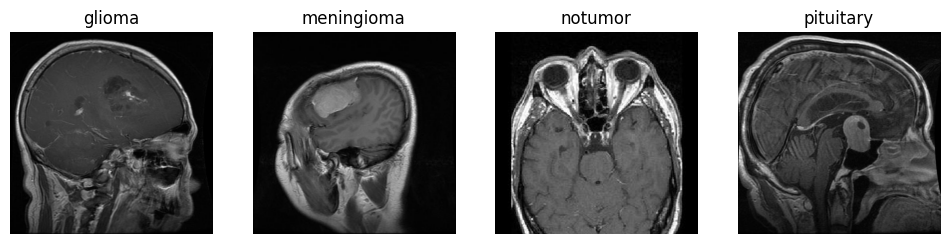

In [3]:
AUTOTUNE = tf.data.AUTOTUNE
def load(path, y):
    img = tf.io.decode_image(tf.io.read_file(path), channels=3, expand_animations=False)  # grayscale -> 3ch
    return tf.image.resize(img, (IMG, IMG)), y                                          # float32, 0..255

def make_ds(df, training=False):
    ds = tf.data.Dataset.from_tensor_slices((df.path.values, df.y.values))
    if training: ds = ds.shuffle(len(df), seed=SEED)
    return ds.map(load, num_parallel_calls=AUTOTUNE).batch(BATCH).prefetch(AUTOTUNE)

train_ds, val_ds, test_ds = make_ds(train, True), make_ds(val), make_ds(test)

fig, ax = plt.subplots(1, 4, figsize=(12, 3))
for i, c in enumerate(CLASS_NAMES):
    ax[i].imshow(Image.open(train[train.y == i].path.iloc[0]).convert("RGB")); ax[i].set_title(c); ax[i].axis("off")
plt.savefig(ASSETS/"samples.png", dpi=150, bbox_inches="tight"); plt.show()

## 2. Model
Preprocessing lives **inside** the model (`Rescaling(1/127.5, -1)` is exactly the ResNet50V2/MobileNetV2 preprocessing), so serving only needs to resize to 224x224 and feed raw 0-255 RGB. Augmentation layers are active only in training: small rotation, shift, zoom and contrast. No flips, since brain orientation carries meaning.

In [4]:
ARCHS = {"resnet50v2": keras.applications.ResNet50V2, "mobilenetv2": keras.applications.MobileNetV2}

def build_model(arch, dropout=0.3):
    base = ARCHS[arch](include_top=False, weights="imagenet", input_shape=(IMG, IMG, 3), name=f"{arch}_base")
    base.trainable = False
    aug = keras.Sequential([layers.RandomRotation(0.05), layers.RandomTranslation(0.05, 0.05),
                            layers.RandomZoom(0.1), layers.RandomContrast(0.1)], name="augment")
    inp = keras.Input((IMG, IMG, 3))
    x = aug(inp)
    x = layers.Rescaling(1/127.5, offset=-1, name="prep")(x)
    x = base(x, training=False)
    x = layers.GlobalAveragePooling2D(name="gap")(x)
    x = layers.Dropout(dropout, name="drop")(x)
    out = layers.Dense(len(CLASS_NAMES), activation="softmax", name="out")(x)
    return keras.Model(inp, out, name=arch), base

class EpochTimer(keras.callbacks.Callback):
    def on_train_begin(self, logs=None): self.times = []
    def on_epoch_begin(self, e, logs=None): self.t = time.perf_counter()
    def on_epoch_end(self, e, logs=None): self.times.append(time.perf_counter() - self.t)

def compile_(model, lr):
    model.compile(keras.optimizers.Adam(lr), "sparse_categorical_crossentropy", metrics=["accuracy"])

def evaluate(model, ds, y_true):
    prob = model.predict(ds, verbose=0); y_pred = prob.argmax(1)
    p, r, f, _ = precision_recall_fscore_support(y_true, y_pred, average="macro", zero_division=0)
    return dict(accuracy=accuracy_score(y_true, y_pred), precision=p, recall=r, f1=f), y_pred, prob

def train_arch(arch, lr1=1e-3, lr2=1e-5, ep1=5, ep2=15, unfreeze=40, dropout=0.3):
    """Phase 1: frozen backbone, train head. Phase 2: unfreeze top layers (BatchNorm kept frozen), low LR."""
    model, base = build_model(arch, dropout)
    timer = EpochTimer()
    cbs = lambda: [keras.callbacks.EarlyStopping(patience=4, restore_best_weights=True),
                   keras.callbacks.ReduceLROnPlateau(factor=0.3, patience=2), timer]
    compile_(model, lr1)
    h1 = model.fit(train_ds, validation_data=val_ds, epochs=ep1, callbacks=cbs(), verbose=2)
    phase1 = evaluate(model, test_ds, test.y.values)[0]

    base.trainable = True
    for l in base.layers[:-unfreeze]: l.trainable = False
    for l in base.layers:
        if isinstance(l, layers.BatchNormalization): l.trainable = False
    compile_(model, lr2)
    h2 = model.fit(train_ds, validation_data=val_ds, epochs=ep1 + ep2, initial_epoch=len(h1.epoch),
                   callbacks=cbs(), verbose=2)
    hist = {k: h1.history[k] + h2.history[k] for k in h1.history}
    return dict(arch=arch, model=model, base=base, hist=hist, phase1_epochs=len(h1.epoch),
                phase1_test=phase1, epoch_times=timer.times, params=model.count_params(),
                hp=dict(lr1=lr1, lr2=lr2, ep1=ep1, ep2=ep2, unfreeze=unfreeze, dropout=dropout, batch=BATCH))

## 3. Train: ResNet50V2 (main) and MobileNetV2 (architecture comparison)

In [5]:
runs = {}
runs["resnet50v2"] = train_arch("resnet50v2")

94668760/94668760 ━━━━━━━━━━━━━━━━━━━━ 21s 0us/step
Epoch 1/5
149/149 - 164s - 1s/step - accuracy: 0.7155 - loss: 0.7231 - val_accuracy: 0.8190 - val_loss: 0.4613 - learning_rate: 0.0010
Epoch 2/5
149/149 - 161s - 1s/step - accuracy: 0.8399 - loss: 0.4290 - val_accuracy: 0.8798 - val_loss: 0.3412 - learning_rate: 0.0010
Epoch 3/5
149/149 - 147s - 984ms/step - accuracy: 0.8582 - loss: 0.3690 - val_accuracy: 0.8679 - val_loss: 0.3481 - learning_rate: 0.0010
Epoch 4/5
149/149 - 147s - 985ms/step - accuracy: 0.8739 - loss: 0.3488 - val_accuracy: 0.8917 - val_loss: 0.3029 - learning_rate: 0.0010
Epoch 5/5
149/149 - 165s - 1s/step - accuracy: 0.8800 - loss: 0.3216 - val_accuracy: 0.8952 - val_loss: 0.2700 - learning_rate: 0.0010
Epoch 6/20
149/149 - 207s - 1s/step - accuracy: 0.9055 - loss: 0.2556 - val_accuracy: 0.9238 - val_loss: 0.1974 - learning_rate: 1.0000e-05
Epoch 7/20
149/149 - 213s - 1s/step - accuracy: 0.9290 - loss: 0.1886 - val_accuracy: 0.9321 - val_loss: 0.1714 - learning_rate

In [6]:
runs["mobilenetv2"] = train_arch("mobilenetv2")

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
Epoch 1/5
149/149 - 91s - 607ms/step - accuracy: 0.7303 - loss: 0.6837 - val_accuracy: 0.8369 - val_loss: 0.4437 - learning_rate: 0.0010
Epoch 2/5
149/149 - 78s - 522ms/step - accuracy: 0.8412 - loss: 0.4388 - val_accuracy: 0.8226 - val_loss: 0.4884 - learning_rate: 0.0010
Epoch 3/5
149/149 - 85s - 572ms/step - accuracy: 0.8601 - loss: 0.3842 - val_accuracy: 0.8060 - val_loss: 0.5395 - learning_rate: 0.0010
Epoch 4/5
149/149 - 84s - 564ms/step - accuracy: 0.8697 - loss: 0.3569 - val_accuracy: 0.8107 - val_loss: 0.5001 - learning_rate: 3.0000e-04
Epoch 5/5
149/149 - 80s - 539ms/step - accuracy: 0.8784 - loss: 0.3308 - val_accuracy: 0.8298 - val_loss: 0.4646 - learning_rate: 3.0000e-04
Epoch 6/20
149/149 - 81s - 543ms/step - accuracy: 0.8441 - loss: 0.4120 - val_accuracy: 0.8488 - val_loss: 0.4132 - learning_rate: 1.0000e-05
Epoch 7/20
149/149 - 86s - 577ms/step - accuracy: 0.8790 - loss: 0.3383 - val_accuracy: 0.8571 - val_loss: 0.4092 - 

## 4. Evaluation

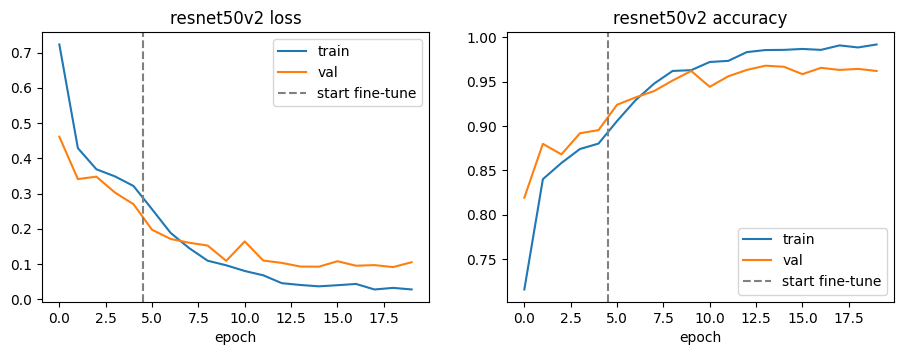

=== resnet50v2 (test) ===
              precision    recall  f1-score   support

      glioma     0.9875    0.7875    0.8762       400
  meningioma     0.8639    0.9525    0.9061       400
     notumor     0.9434    1.0000    0.9709       400
   pituitary     0.9495    0.9875    0.9681       400

    accuracy                         0.9319      1600
   macro avg     0.9361    0.9319    0.9303      1600
weighted avg     0.9361    0.9319    0.9303      1600



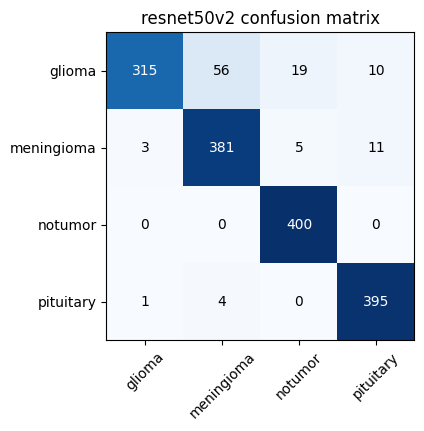

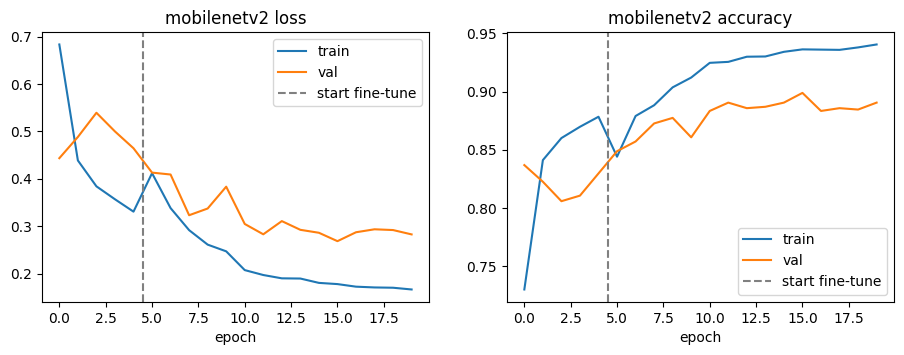

=== mobilenetv2 (test) ===
              precision    recall  f1-score   support

      glioma     0.9514    0.6850    0.7965       400
  meningioma     0.7696    0.7100    0.7386       400
     notumor     0.9065    0.9700    0.9372       400
   pituitary     0.7709    0.9925    0.8678       400

    accuracy                         0.8394      1600
   macro avg     0.8496    0.8394    0.8350      1600
weighted avg     0.8496    0.8394    0.8350      1600



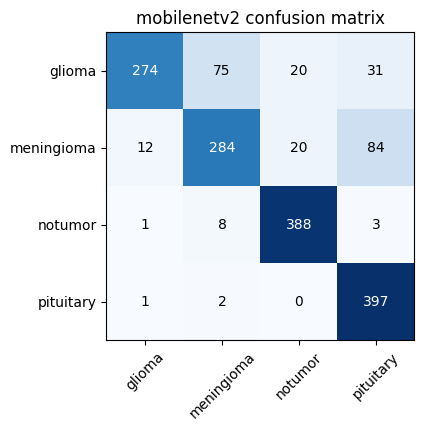

,params (M),mean s/epoch,best val acc,test acc (head only),test accuracy,test precision,test recall,test f1
resnet50v2,23.5730,203.4062,0.9679,0.8512,0.9319,0.9361,0.9319,0.9303
mobilenetv2,2.2631,79.7175,0.8988,0.7769,0.8394,0.8496,0.8394,0.8350


In [7]:
def plot_curves(r):
    h, k = r["hist"], r["phase1_epochs"]
    fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
    for a, m in zip(ax, ["loss", "accuracy"]):
        a.plot(h[m], label="train"); a.plot(h["val_" + m], label="val")
        a.axvline(k - 0.5, ls="--", c="gray", label="start fine-tune"); a.set_title(f"{r['arch']} {m}"); a.set_xlabel("epoch"); a.legend()
    plt.savefig(ASSETS/f"curves_{r['arch']}.png", dpi=150, bbox_inches="tight"); plt.show()

results = {}
for name, r in runs.items():
    plot_curves(r)
    m, y_pred, prob = evaluate(r["model"], test_ds, test.y.values)
    r["test"], r["y_pred"] = m, y_pred
    print(f"=== {name} (test) ==="); print(classification_report(test.y, y_pred, target_names=CLASS_NAMES, digits=4))
    cm = confusion_matrix(test.y, y_pred)
    plt.figure(figsize=(4.5, 4)); plt.imshow(cm, cmap="Blues"); plt.title(f"{name} confusion matrix")
    plt.xticks(range(4), CLASS_NAMES, rotation=45); plt.yticks(range(4), CLASS_NAMES)
    for i in range(4):
        for j in range(4): plt.text(j, i, cm[i, j], ha="center", va="center", color="white" if cm[i, j] > cm.max()/2 else "black")
    plt.savefig(ASSETS/f"cm_{name}.png", dpi=150, bbox_inches="tight"); plt.show()
    results[name] = dict(params=r["params"], mean_epoch_s=float(np.mean(r["epoch_times"])), total_train_s=float(sum(r["epoch_times"])),
                         best_val_acc=float(max(r["hist"]["val_accuracy"])), test=m, test_after_phase1_only=r["phase1_test"], hp=r["hp"])

comparison = pd.DataFrame({n: {"params (M)": v["params"]/1e6, "mean s/epoch": v["mean_epoch_s"], "best val acc": v["best_val_acc"],
                               "test acc (head only)": v["test_after_phase1_only"]["accuracy"],
                               **{f"test {k}": x for k, x in v["test"].items()}} for n, v in results.items()}).T.round(4)
display(comparison)

## 5. Interpretability: Grad-CAM
Gradient of the predicted class score w.r.t. the last convolutional feature map, channel-averaged, ReLU, upsampled onto the image.

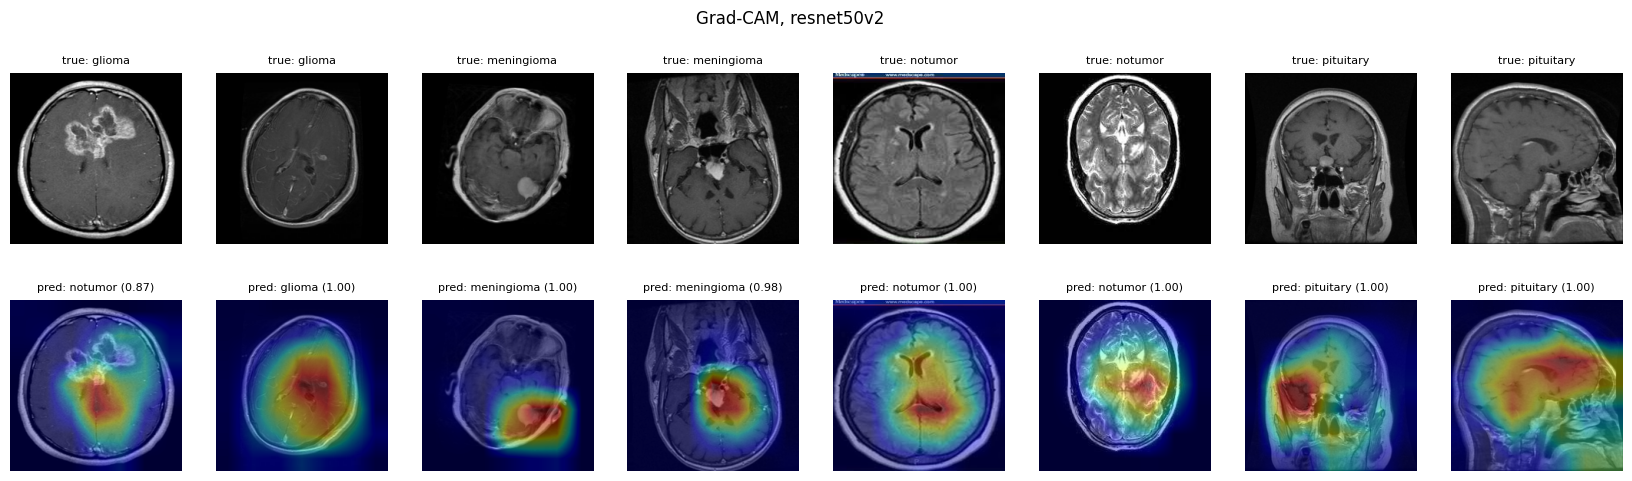

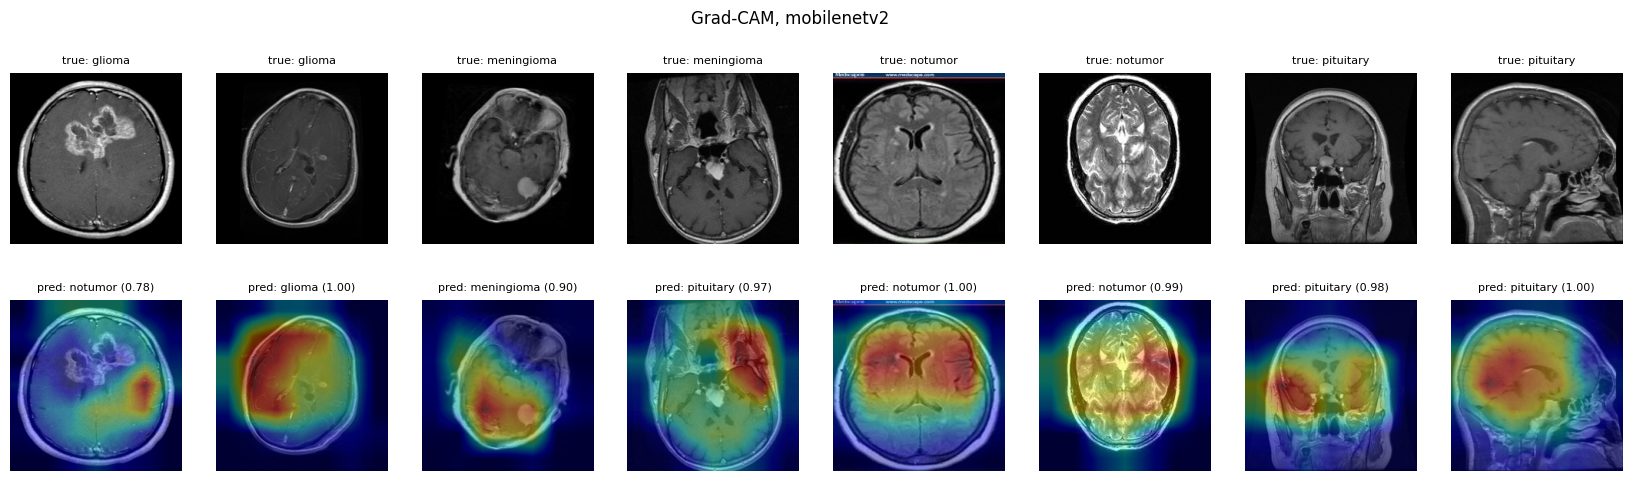

In [8]:
def make_gradcam(model, base):
    last = next(l.name for l in reversed(base.layers) if len(l.output.shape) == 4)
    feat = keras.Model(base.input, [base.get_layer(last).output, base.output])
    prep, gap, drop, out = (model.get_layer(n) for n in ["prep", "gap", "drop", "out"])
    def cam(img, k=None):
        x = prep(tf.convert_to_tensor(img[None], tf.float32))
        with tf.GradientTape() as t:
            conv, f = feat(x, training=False)
            p = out(drop(gap(f), training=False))
            k = int(tf.argmax(p[0])) if k is None else k
            score = p[:, k]
        g = t.gradient(score, conv)
        w = tf.reduce_mean(g, axis=(1, 2), keepdims=True)
        c = tf.nn.relu(tf.reduce_sum(w * conv, axis=-1))[0]
        c = (c / (tf.reduce_max(c) + 1e-8))[..., None]
        return tf.image.resize(c, (IMG, IMG))[..., 0].numpy(), k, p[0].numpy()
    return cam

def show_gradcam(name, n_per_class=2):
    r = runs[name]; cam = make_gradcam(r["model"], r["base"])
    rows = [test[test.y == c].iloc[i] for c in range(4) for i in range(n_per_class)]
    fig, ax = plt.subplots(2, len(rows), figsize=(2.6 * len(rows), 5.4))
    for j, row in enumerate(rows):
        img = np.asarray(Image.open(row.path).convert("RGB").resize((IMG, IMG)), dtype="float32")
        heat, k, p = cam(img)
        ax[0, j].imshow(img.astype("uint8")); ax[0, j].set_title(f"true: {CLASS_NAMES[row.y]}", fontsize=8); ax[0, j].axis("off")
        ax[1, j].imshow(img.astype("uint8")); ax[1, j].imshow(heat, cmap="jet", alpha=0.4)
        ax[1, j].set_title(f"pred: {CLASS_NAMES[k]} ({p[k]:.2f})", fontsize=8); ax[1, j].axis("off")
    plt.suptitle(f"Grad-CAM, {name}"); plt.savefig(ASSETS/f"gradcam_{name}.png", dpi=150, bbox_inches="tight"); plt.show()

for n in runs: show_gradcam(n)

## 6. Pick the model to export and verify serving parity
Selection by **validation** accuracy (not test). The check below runs the exact preprocessing a FastAPI service will use (PIL, RGB, bilinear resize to 224, raw 0-255 floats) and compares it with the training pipeline.

In [9]:
best = max(runs, key=lambda n: results[n]["best_val_acc"]); print("selected by val acc:", best)
model = runs[best]["model"]
path = MODEL_DIR / f"model_{TEAM_ID}.keras"; model.save(path)
print(f"saved {path}  ({path.stat().st_size/1e6:.1f} MB)")

def serve_pre(p):   # <- copy this into app/main.py
    return np.asarray(Image.open(p).convert("RGB").resize((IMG, IMG), Image.BILINEAR), dtype="float32")

reloaded = keras.models.load_model(path)
pred = np.concatenate([reloaded.predict(np.stack([serve_pre(p) for p in test.path.values[i:i+64]]), verbose=0).argmax(1)
                       for i in range(0, len(test), 64)])
print("test acc via PIL serving path:", accuracy_score(test.y, pred), "| training-pipeline acc:", results[best]["test"]["accuracy"])

selected by val acc: resnet50v2
saved ..\model\model_T10.keras  (216.8 MB)
test acc via PIL serving path: 0.938125 | training-pipeline acc: 0.931875


In [10]:
# CPU single-image latency (the service runs on CPU), for both models
lat = {}
x = serve_pre(test.path.iloc[0])[None]
with tf.device("/CPU:0"):
    for n, r in runs.items():
        r["model"](x, training=False)                       # warm-up
        t0 = time.perf_counter()
        for _ in range(50): r["model"](x, training=False).numpy()
        lat[n] = (time.perf_counter() - t0) / 50 * 1000
for n in results: results[n]["cpu_latency_ms"] = lat[n]
print({n: f"{v:.1f} ms" for n, v in lat.items()})

results["_meta"] = dict(selected=best, tf=tf.__version__, gpus=[g.name for g in tf.config.list_physical_devices("GPU")],
                        split=summary.to_dict("index"))
json.dump(results, open(ASSETS/"tf_results.json", "w"), indent=2, default=float)

{'resnet50v2': '188.7 ms', 'mobilenetv2': '117.9 ms'}


## 7. Notes for the report
- **Split:** see table in section 1 (`splits.csv`).
- **Preprocessing / augmentation:** resize 224, 3-channel, scaling to [-1, 1] inside the model; rotation, shift, zoom, contrast.
- **Transfer learning:** ImageNet backbone, 2 phases (frozen head, then top 40 layers with BN frozen at lr 1e-5).
- **Comparison data:** `tf_results.json` has params, time/epoch, CPU latency, metrics, and head-only vs fine-tuned accuracy (training strategy comparison).
- **Limitations to discuss:** single-center Kaggle data, 2D slices (no patient-level split info, possible near-duplicate slices across train/test), only 4 classes, no external validation, Grad-CAM is coarse (7x7 maps).